# Detección de phishing: análisis exploratorio con Pandas

Análisis exploratorio de un dataset de **212.216 URLs** etiquetadas como legítimas o de phishing.
Cada fila tiene features calculadas sobre la URL (largo, cantidad de letras, dígitos, TLD, HTTPS)
y sobre el HTML de la página (líneas de código, referencias, formularios, recursos).

- `label = 1` → página **legítima**
- `label = 0` → página de **phishing**

## Configuración y carga de datos

In [1]:
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.lines import Line2D
from matplotlib.ticker import FuncFormatter

sns.set(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

# Colores usados en todos los gráficos
COLOR_PHISHING = "#FF4500"   # naranja
COLOR_LEGITIMA = "#6495ED"   # celeste

In [2]:
# Descarga del dataset desde Google Drive.
# El archivo está compartido como "Cualquier persona con el enlace", así que no hace falta iniciar sesión.
import os
import gdown

ARCHIVOS = {"train.csv": "1MTwmishpQVBW_iaxbzZiWAVf-sfAsOIJ"}

for nombre, file_id in ARCHIVOS.items():
    if not os.path.exists(nombre):
        gdown.download(id=file_id, output=nombre, quiet=True)

In [3]:
df = pd.read_csv("train.csv")

# Columna auxiliar con el nombre de la clase, útil para los gráficos
df["clase"] = df["label"].map({0: "Phishing", 1: "Legítima"})
PALETA = {"Phishing": COLOR_PHISHING, "Legítima": COLOR_LEGITIMA}

print(df.shape)
df.head()

(212216, 58)


,Unnamed: 0,FILENAME,URL,URLLength,Domain,DomainLength,IsDomainIP,TLD,URLSimilarityIndex,CharContinuationRate,...,Crypto,HasCopyrightInfo,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef,label,clase
0,136221,827598.txt,https://www.northcm.ac.th,24,www.northcm.ac.th,17,0,th,100.000000,0.800000,...,0,1,47,3,4,69,7,115,1,Legítima
1,56609,oph00308.txt,https://unitedmartialartscenters.com/at0/mygov...,59,unitedmartialartscenters.com,28,0,com,33.522664,1.000000,...,0,1,0,2,0,0,0,1,0,Phishing
2,46393,8112660.txt,https://email.mail1.onesignal.os.tc/c/ejwcz02u...,385,email.mail1.onesignal.os.tc,27,0,tc,3.199329,0.458333,...,0,0,0,0,0,0,0,1,0,Phishing
3,129746,8135291.txt,http://uqr.to/1il1z,19,uqr.to,6,0,to,53.846154,1.000000,...,0,0,0,0,0,1,0,1,0,Phishing
4,131464,586561.txt,https://www.woolworthsrewards.com.au,35,www.woolworthsrewards.com.au,28,0,au,100.000000,0.857143,...,0,1,33,7,8,15,0,2,1,Legítima


## Pregunta 1: ¿Cuál es la proporción de URLs no legítimas?

In [4]:
cant_legitimas = (df["label"] == 1).sum()
cant_phishing = (df["label"] == 0).sum()
cant_total = len(df)

print(f"Páginas legítimas: {cant_legitimas}")
print(f"Páginas de phishing: {cant_phishing}")
print(f"Total: {cant_total}")
print(f"Proporción de phishing: {cant_phishing / cant_total:.2%}")

Páginas legítimas: 121415
Páginas de phishing: 90801
Total: 212216
Proporción de phishing: 42.79%


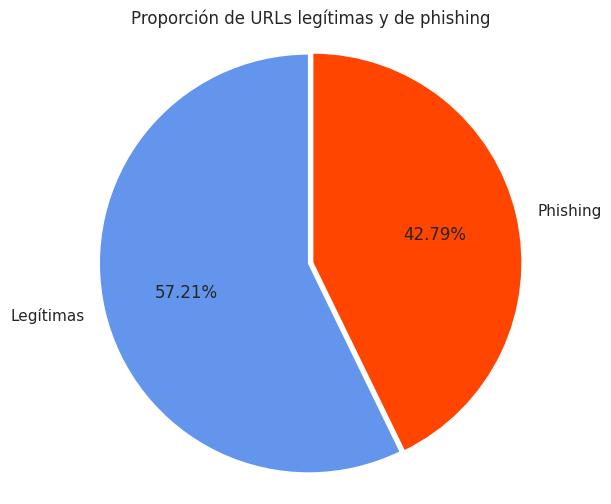

In [5]:
plt.figure(figsize=(6, 6))
plt.pie(
    [cant_legitimas, cant_phishing],
    labels=["Legítimas", "Phishing"],
    autopct="%1.2f%%",
    startangle=90,
    colors=[COLOR_LEGITIMA, COLOR_PHISHING],
    explode=(0.01, 0.01),
)
plt.title("Proporción de URLs legítimas y de phishing")
plt.axis("equal")
plt.show()

### Respuesta

El **42,79%** de las URLs del dataset son de phishing (90.801 de 212.216), una proporción muy alta.
Las dos clases están relativamente balanceadas, lo que facilita compararlas.

## Pregunta 2: ¿Qué relación hay entre el largo y la composición de la URL (letras, números y caracteres especiales) y el label?

In [6]:
columnas_ratio = ["DomainLength", "LetterRatioInURL", "DegitRatioInURL", "SpacialCharRatioInURL"]
columnas_cantidad = ["NoOfLettersInURL", "NoOfDegitsInURL", "NoOfOtherSpecialCharsInURL"]

df.groupby("clase")[columnas_ratio + columnas_cantidad].mean()

,DomainLength,LetterRatioInURL,DegitRatioInURL,SpacialCharRatioInURL,NoOfLettersInURL,NoOfDegitsInURL,NoOfOtherSpecialCharsInURL
clase,,,,,,,
Legítima,19.230713,0.476750,0.002104,0.048369,12.934942,0.05029,1.245349
Phishing,24.460138,0.568217,0.064067,0.083291,28.081001,4.29905,3.792227


### Verificación de consistencia del dataset

Al revisar las primeras filas, los conteos no coinciden con lo que se ve en la URL.
Por ejemplo, en `https://www.northcm.ac.th` el dataset indica 10 letras, mientras que la URL completa tiene 19.
El dataset no documenta sobre qué parte de la URL se hizo el conteo, así que recalculo las columnas
sobre la URL completa y comparo.

In [7]:
df[["URL", "URLLength", "NoOfLettersInURL", "NoOfDegitsInURL", "NoOfOtherSpecialCharsInURL"]].head()

,URL,URLLength,NoOfLettersInURL,NoOfDegitsInURL,NoOfOtherSpecialCharsInURL
0,https://www.northcm.ac.th,24,10,0,2
1,https://unitedmartialartscenters.com/at0/mygov...,59,45,1,5
2,https://email.mail1.onesignal.os.tc/c/ejwcz02u...,385,302,51,24
3,http://uqr.to/1il1z,19,8,2,2
4,https://www.woolworthsrewards.com.au,35,21,0,2


In [8]:
# Recalculo los conteos sobre la URL completa
df["URLLength_calc"] = df["URL"].str.len()
df["NoOfLettersInURL_calc"] = df["URL"].str.count(r"[a-zA-Z]")
df["NoOfDegitsInURL_calc"] = df["URL"].str.count(r"\d")
df["NoOfOtherSpecialCharsInURL_calc"] = df["URL"].str.count(r"[^a-zA-Z0-9]")

comparaciones = {
    "URLLength": "URLLength_calc",
    "NoOfLettersInURL": "NoOfLettersInURL_calc",
    "NoOfDegitsInURL": "NoOfDegitsInURL_calc",
    "NoOfOtherSpecialCharsInURL": "NoOfOtherSpecialCharsInURL_calc",
}
for original, calculada in comparaciones.items():
    distintas = (df[original] != df[calculada]).sum()
    print(f"{original}: {distintas} filas ({distintas / len(df):.1%}) no coinciden con el recálculo")

URLLength: 168422 filas (79.4%) no coinciden con el recálculo
NoOfLettersInURL: 212216 filas (100.0%) no coinciden con el recálculo
NoOfDegitsInURL: 1064 filas (0.5%) no coinciden con el recálculo
NoOfOtherSpecialCharsInURL: 212216 filas (100.0%) no coinciden con el recálculo


In [9]:
# Ejemplos de filas con discrepancias
df[["URL"] + [c for par in comparaciones.items() for c in par]].head(10)

,URL,URLLength,URLLength_calc,NoOfLettersInURL,NoOfLettersInURL_calc,NoOfDegitsInURL,NoOfDegitsInURL_calc,NoOfOtherSpecialCharsInURL,NoOfOtherSpecialCharsInURL_calc
0,https://www.northcm.ac.th,24,25,10,19,0,0,2,6
1,https://unitedmartialartscenters.com/at0/mygov...,59,60,45,51,1,1,5,8
2,https://email.mail1.onesignal.os.tc/c/ejwcz02u...,385,385,302,307,51,51,24,27
3,http://uqr.to/1il1z,19,19,8,12,2,2,2,5
4,https://www.woolworthsrewards.com.au,35,36,21,30,0,0,2,6
5,https://www.kubiena-kochblog.com,31,32,17,26,0,0,2,6
6,https://couchjumper.com/covantage/index.html,44,44,32,37,0,0,4,7
7,http://www.rightnowscope.com,27,28,15,23,0,0,1,5
8,http://u1965047.plsk.regruhosting.ru/47/,40,40,19,23,9,9,5,8
9,http://www.unblock-me.org,24,25,11,19,0,0,2,6


In [10]:
# Ratios recalculados (cantidad / largo total de la URL)
df["LetterRatioInURL_calc"] = df["NoOfLettersInURL_calc"] / df["URLLength_calc"]
df["DegitRatioInURL_calc"] = df["NoOfDegitsInURL_calc"] / df["URLLength_calc"]
df["SpacialCharRatioInURL_calc"] = df["NoOfOtherSpecialCharsInURL_calc"] / df["URLLength_calc"]

columnas_calc = [
    "URLLength_calc",
    "NoOfLettersInURL_calc", "NoOfDegitsInURL_calc", "NoOfOtherSpecialCharsInURL_calc",
    "LetterRatioInURL_calc", "DegitRatioInURL_calc", "SpacialCharRatioInURL_calc",
]
df.groupby("clase")[columnas_calc].mean().round(3)

,URLLength_calc,NoOfLettersInURL_calc,NoOfDegitsInURL_calc,NoOfOtherSpecialCharsInURL_calc,LetterRatioInURL_calc,DegitRatioInURL_calc,SpacialCharRatioInURL_calc
clase,,,,,,,
Legítima,27.231,21.935,0.050,5.245,0.800,0.002,0.198
Phishing,46.167,34.222,4.311,7.634,0.747,0.064,0.189


### Respuesta

Con los valores recalculados, las URLs de phishing tienen en promedio **más letras, dígitos y caracteres especiales**:

| | Phishing | Legítima |
|---|---|---|
| Letras (promedio) | 34,2 | 21,9 |
| Dígitos (promedio) | 4,3 | 0,05 |
| Caracteres especiales (promedio) | 7,6 | 5,2 |
| Ratio de letras | 0,747 | 0,790 |
| Ratio de dígitos | 0,063 | 0,002 |
| Ratio de caracteres especiales | 0,189 | 0,198 |

- Las URLs de phishing son más largas, por eso tienen más de todo en valores absolutos.
- En proporción, letras y caracteres especiales están parejos entre ambas clases.
- La diferencia clara está en los **dígitos**: prácticamente no aparecen en URLs legítimas
  (0,2% de la URL) y sí en las de phishing (6,3%). Es el indicador más fuerte de este grupo.

## Pregunta 3: ¿Qué impacto tienen las self references, empty references y external references en el label?

Hipótesis: una página legítima suele tener muchos enlaces a sus propias secciones y a sitios externos,
mientras que una de phishing suele ser más simple o tener enlaces vacíos.

In [11]:
columnas_ref = ["NoOfSelfRef", "NoOfEmptyRef", "NoOfExternalRef"]
df.groupby("clase")[columnas_ref].agg(["mean", "median"]).round(2)

NoOfSelfRef        NoOfEmptyRef        NoOfExternalRef       
                mean median         mean median            mean median
clase                                                                 
Legítima      113.43   76.0         4.07    1.0           85.23   45.0
Phishing        0.49    0.0         0.15    0.0            1.13    0.0

### Respuesta

Las páginas de phishing tienen muchas menos referencias de los tres tipos:

- **Self references**: 0,49 en promedio en phishing contra 113,43 en legítimas.
- **Empty references**: 0,15 contra 4,06.
- **External references**: 1,12 contra 85,22.

La hipótesis de los enlaces vacíos no se cumple: las páginas de phishing son, en general,
páginas mucho más chicas y con menos enlaces de cualquier tipo.

## Pregunta 4: ¿Las variables Bank, Pay y Crypto tienen impacto sobre el label?

In [12]:
# Como son variables binarias, el promedio es la proporción de páginas que la tienen
df.groupby("clase")[["Bank", "Pay", "Crypto"]].mean().round(4)

,Bank,Pay,Crypto
clase,,,
Legítima,0.1815,0.3689,0.0366
Phishing,0.0545,0.0607,0.0062


In [13]:
# Combinaciones posibles: una página puede ser Bank, Pay y Crypto a la vez
df.groupby("clase")[["Bank", "Pay", "Crypto"]].value_counts().unstack("clase", fill_value=0)

clase            Legítima  Phishing
Bank Pay Crypto                    
0    0   0          67331     82671
         1           1283       289
     1   0          29294      2832
         1           1473        60
1    0   0           7490      2181
         1            526       146
     1   0          12853      2558
         1           1165        64

### Respuesta

Las tres variables aparecen **bastante más en páginas legítimas**:

- **Bank**: 5,5% de las páginas de phishing contra 18,2% de las legítimas.
- **Pay**: 6,1% contra 36,9%.
- **Crypto**: 0,6% contra 3,7%.

Que una página mencione bancos, pagos o cripto no la hace sospechosa en este dataset;
al contrario, es más común en sitios legítimos.

## Pregunta 5: ¿Los campos de contraseña, campos ocultos o botones de submit tienen impacto?

In [14]:
df.groupby("clase")[["HasPasswordField", "HasHiddenFields", "HasSubmitButton"]].mean().round(4)

,HasPasswordField,HasHiddenFields,HasSubmitButton
clase,,,
Legítima,0.1385,0.5905,0.6608
Phishing,0.0543,0.0935,0.0853


### Respuesta

Las tres características son **mucho menos frecuentes en páginas de phishing**:

- **Campo de contraseña**: 5,4% en phishing contra 13,9% en legítimas.
- **Campos ocultos**: 9,4% contra 59,1%.
- **Botón de submit**: 8,5% contra 66,1%.

Es coherente con lo visto en la pregunta 3: las páginas de phishing del dataset son, en su mayoría,
páginas simples, sin formularios ni estructura.

# Visualizaciones

## Gráfico 1: Bank, Pay y Crypto según el tipo de página

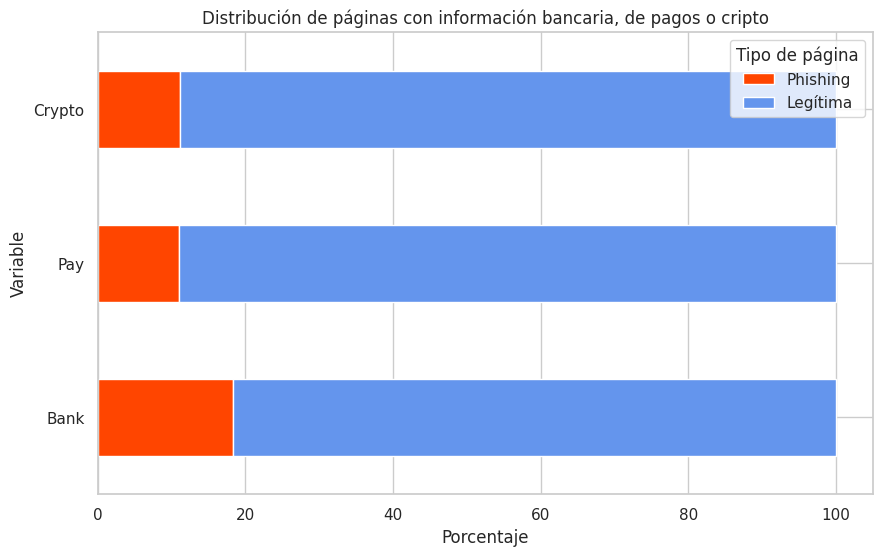

In [15]:
# Para cada variable, qué porcentaje de las páginas que la tienen son phishing o legítimas
stacked = df.groupby("clase")[["Bank", "Pay", "Crypto"]].sum()
stacked = stacked.div(stacked.sum(axis=0), axis=1) * 100

stacked.T[["Phishing", "Legítima"]].plot(
    kind="barh", stacked=True, color=[COLOR_PHISHING, COLOR_LEGITIMA]
)
plt.title("Distribución de páginas con información bancaria, de pagos o cripto")
plt.xlabel("Porcentaje")
plt.ylabel("Variable")
plt.legend(title="Tipo de página")
plt.show()

## Gráfico 2: Líneas de código vs. largo de la línea más larga

In [16]:
print("Correlación de Pearson:")
df[["LineOfCode", "LargestLineLength"]].corr()

Correlación de Pearson:


,LineOfCode,LargestLineLength
LineOfCode,1.000000,0.006921
LargestLineLength,0.006921,1.000000


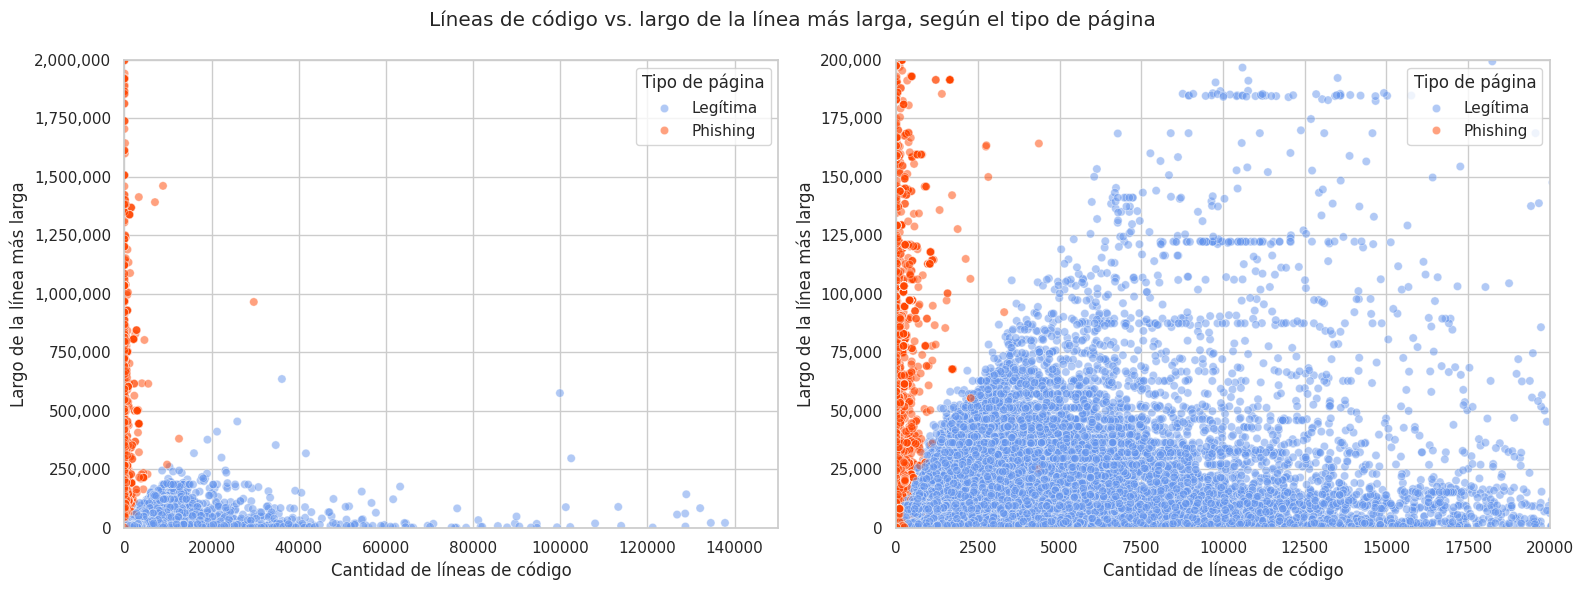

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Dos vistas con distintos límites, para ver los valores extremos y la zona más densa
limites = [(150_000, 2_000_000), (20_000, 200_000)]

for ax, (xmax, ymax) in zip(axes, limites):
    sns.scatterplot(
        data=df, x="LineOfCode", y="LargestLineLength",
        hue="clase", palette=PALETA, alpha=0.5, ax=ax,
    )
    ax.set_xlim(0, xmax)
    ax.set_ylim(0, ymax)
    ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:,.0f}"))
    ax.set_xlabel("Cantidad de líneas de código")
    ax.set_ylabel("Largo de la línea más larga")
    ax.legend(title="Tipo de página")

fig.suptitle("Líneas de código vs. largo de la línea más larga, según el tipo de página")
plt.tight_layout()
plt.show()

In [18]:
resumen_codigo = df.groupby("clase")[["LineOfCode", "LargestLineLength"]].median()
print("Medianas por tipo de página:")
print(resumen_codigo)
print()

for columna, descripcion in [("LineOfCode", "líneas de código"), ("LargestLineLength", "largo de línea más larga")]:
    mayor = resumen_codigo[columna].idxmax()
    print(f"Las páginas de tipo '{mayor}' tienen una mediana de {descripcion} más alta.")

Medianas por tipo de página:
          LineOfCode  LargestLineLength
clase                                  
Legítima      1104.0             3060.0
Phishing        11.0              136.0

Las páginas de tipo 'Legítima' tienen una mediana de líneas de código más alta.
Las páginas de tipo 'Legítima' tienen una mediana de largo de línea más larga más alta.


La correlación de Pearson entre ambas variables es prácticamente nula (0,0069): saber cuántas líneas
tiene una página no dice nada sobre el largo de su línea más larga. Puede haber páginas con pocas líneas
y una línea larguísima (HTML minificado), o con muchas líneas cortas.

Las medianas de la celda anterior muestran cuál de los dos tipos de página es más grande.
Uso la mediana y no el promedio porque las dos variables tienen outliers enormes.

## Gráfico 3: Distribución del largo de las URLs

In [19]:
# El describe sirve para ver los outliers y elegir un límite razonable para el histograma
df["URLLength"].describe()

,URLLength
count,212216.000000
mean,34.539285
std,40.138927
min,13.000000
25%,23.000000
50%,27.000000
75%,34.000000
max,6097.000000


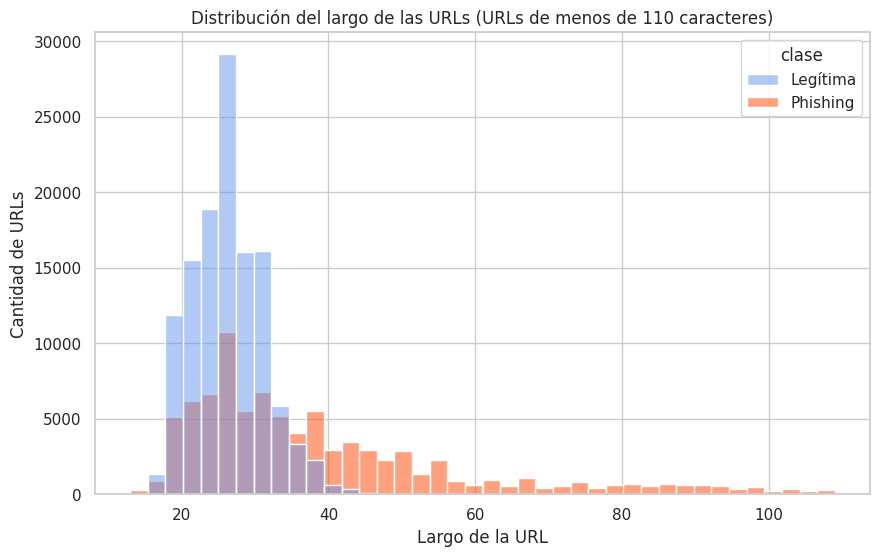

In [20]:
plt.figure(figsize=(10, 6))
sns.histplot(
    data=df[df["URLLength"] < 110], x="URLLength", hue="clase",
    palette=PALETA, bins=40, multiple="layer", alpha=0.5,
)
plt.title("Distribución del largo de las URLs (URLs de menos de 110 caracteres)")
plt.xlabel("Largo de la URL")
plt.ylabel("Cantidad de URLs")
plt.show()

## Gráfico 4: URLs de phishing por largo de URL, largo de dominio, TLD y dígitos

Gráfico de burbujas con cuatro variables: largo de la URL (eje X), largo del dominio (eje Y),
TLD (color) y cantidad de dígitos (tamaño de la burbuja). Solo los 6 TLDs más frecuentes en phishing.

In [21]:
df_phishing = df[df["label"] == 0]
print(df_phishing["TLD"].value_counts().head(10))

TLD
com     39350
app      5751
co       4446
io       3384
net      2782
ru       2695
top      2102
dev      2098
org      2055
site     1321
Name: count, dtype: int64


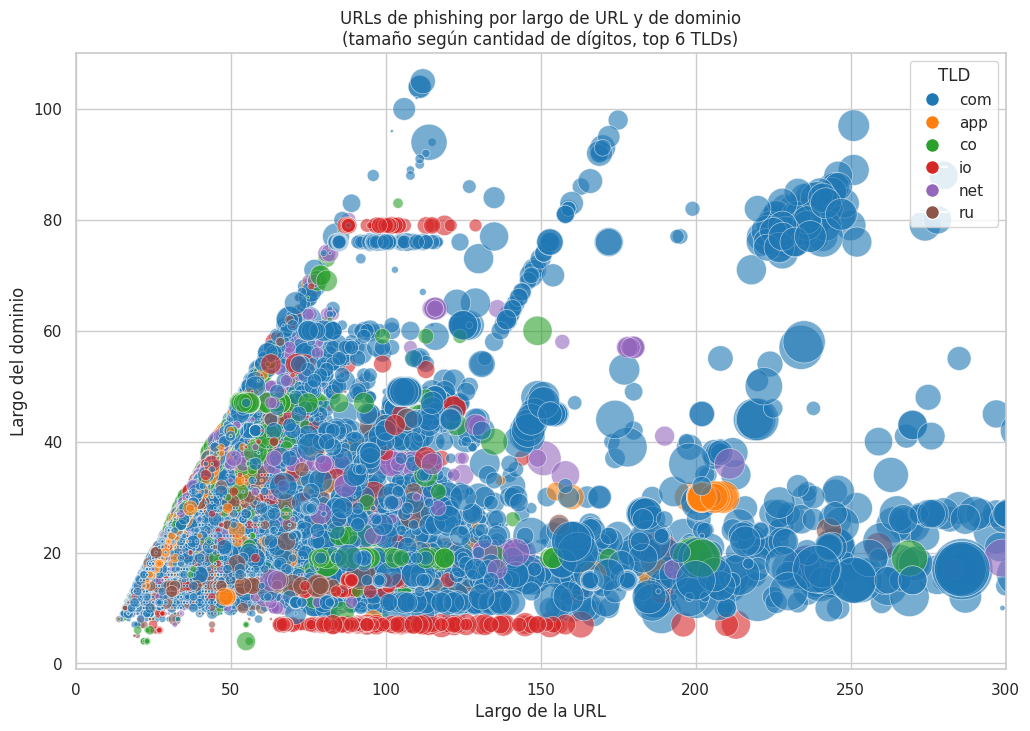

In [22]:
top_tlds = df_phishing["TLD"].value_counts().head(6).index
df_burbujas = df_phishing[df_phishing["TLD"].isin(top_tlds)].copy()

tab10 = matplotlib.colormaps["tab10"]
colores_tld = {tld: tab10(i) for i, tld in enumerate(top_tlds)}

plt.figure(figsize=(12, 8))
plt.scatter(
    df_burbujas["URLLength"], df_burbujas["DomainLength"],
    s=df_burbujas["NoOfDegitsInURL"] * 10 + 5,   # +5 para que se vean las URLs sin dígitos
    c=df_burbujas["TLD"].map(colores_tld),
    alpha=0.6, edgecolors="w", linewidth=0.5,
)
plt.title("URLs de phishing por largo de URL y de dominio\n(tamaño según cantidad de dígitos, top 6 TLDs)")
plt.xlabel("Largo de la URL")
plt.ylabel("Largo del dominio")
plt.xlim(0, 300)

leyenda = [
    Line2D([0], [0], marker="o", color="w", label=tld, markerfacecolor=colores_tld[tld], markersize=10)
    for tld in top_tlds
]
plt.legend(handles=leyenda, title="TLD", loc="upper right")
plt.show()

## Extra: cantidad de páginas de phishing por TLD

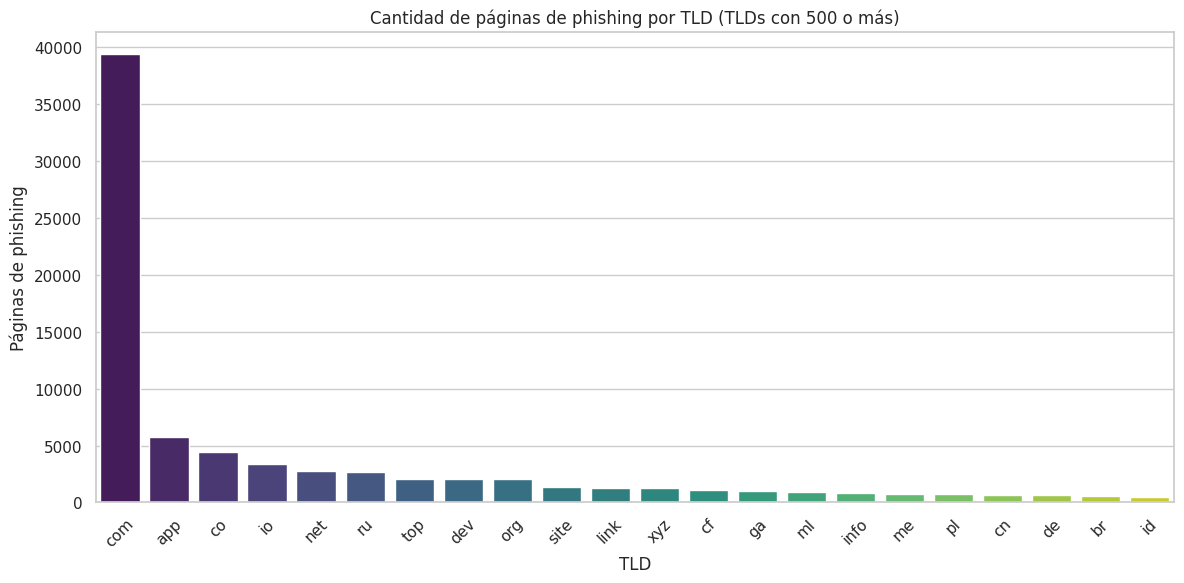

In [23]:
phishing_por_tld = (
    df_phishing.groupby("TLD").size()
    .reset_index(name="cantidad_phishing")
    .query("cantidad_phishing >= 500")          # TLDs con al menos 500 páginas de phishing
    .sort_values("cantidad_phishing", ascending=False)
)

plt.figure(figsize=(12, 6))
sns.barplot(data=phishing_por_tld, x="TLD", y="cantidad_phishing", hue="TLD", palette="viridis", legend=False)
plt.title("Cantidad de páginas de phishing por TLD (TLDs con 500 o más)")
plt.xlabel("TLD")
plt.ylabel("Páginas de phishing")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Extra: HTTPS y legitimidad

In [24]:
legitimas = df[df["label"] == 1]
con_https = df[df["IsHTTPS"] == 1]

print(f"{(legitimas['IsHTTPS'] == 1).mean():.2%} de las páginas legítimas usan HTTPS")
print(f"{(con_https['label'] == 1).mean():.2%} de las páginas con HTTPS son legítimas")
print(f"{(df[df['IsHTTPS'] == 0]['label'] == 0).mean():.2%} de las páginas sin HTTPS son phishing")

100.00% de las páginas legítimas usan HTTPS
73.12% de las páginas con HTTPS son legítimas
100.00% de las páginas sin HTTPS son phishing


HTTPS funciona como **filtro negativo**: una página sin HTTPS es casi con seguridad phishing.
Pero no sirve como filtro positivo, porque muchas páginas de phishing también usan HTTPS.